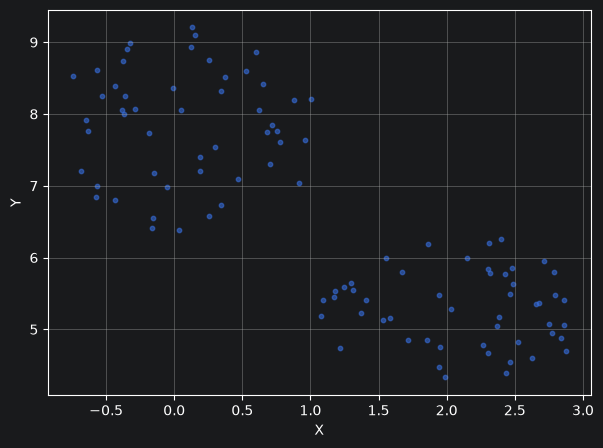

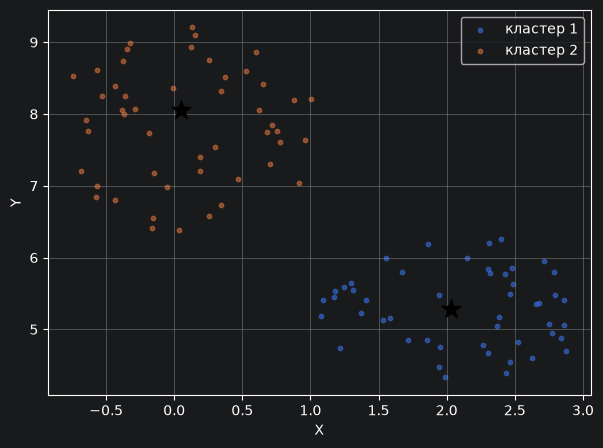

X = 1041.01  Y = 6671.17


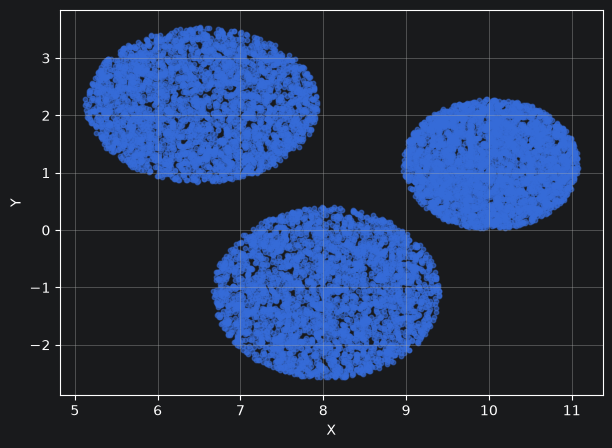

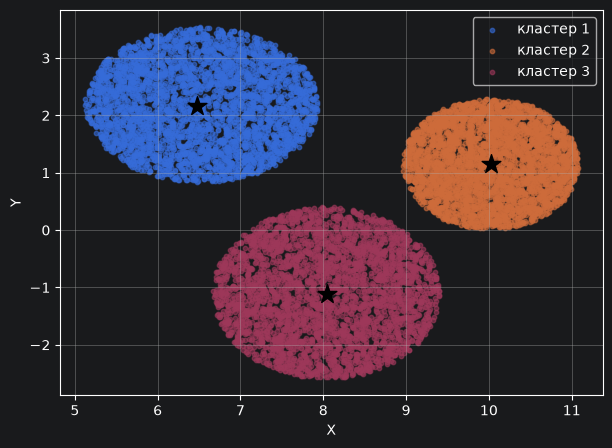

X = 8177.53  Y = 738.42


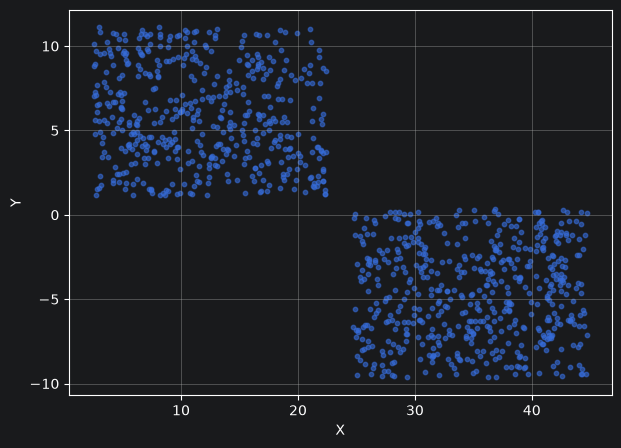

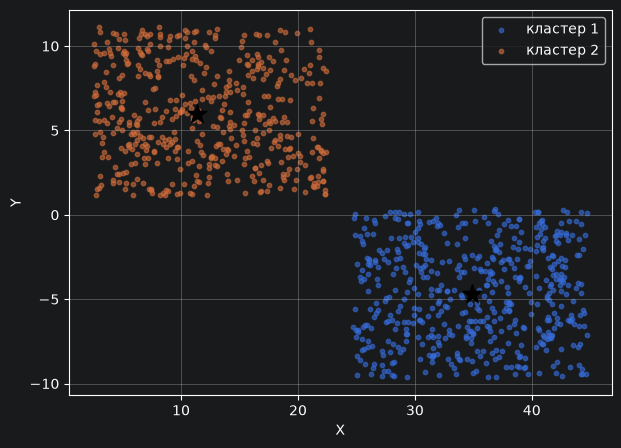

X = 23130.22  Y = 635.34


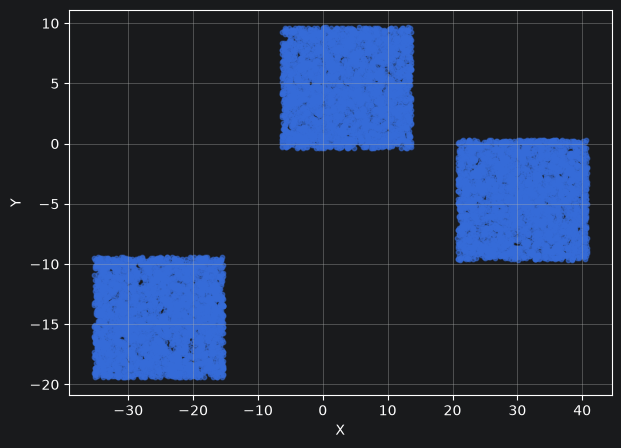

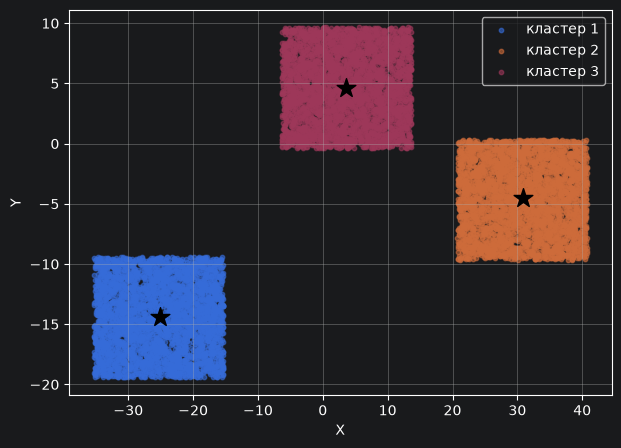

X = 3078.89  Y = -4758.95


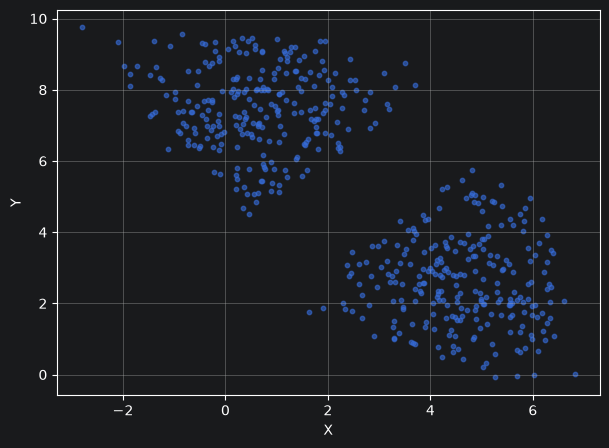

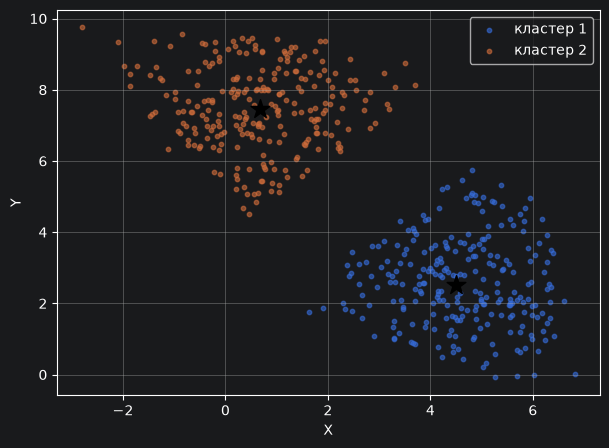

X = 2588.54  Y = 4996.57


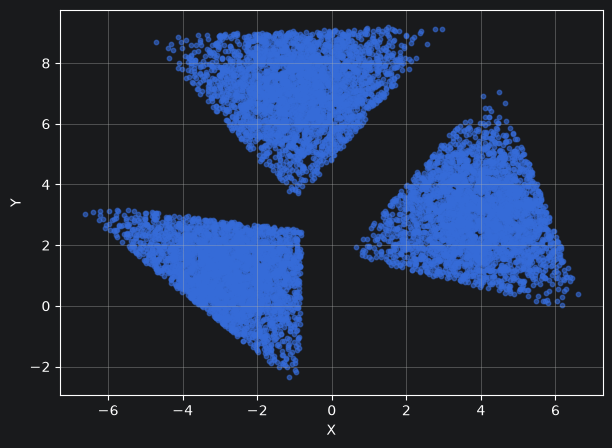

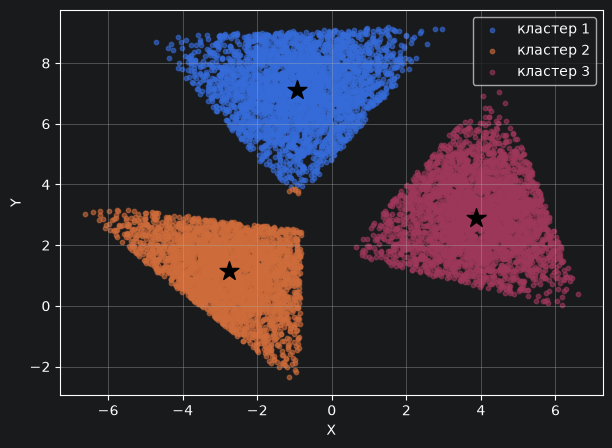

X = 61.65  Y = 3723.36


In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial.distance import cdist
from sklearn.cluster import KMeans

plt.rcParams['figure.figsize'] = (7, 5)
plt.rcParams['axes.grid'] = True


def load(file):
    df = pd.read_excel(file)
    if "X" in df.columns:
        return df[["X", "Y"]].values
    df = pd.read_excel(file, header=None)
    return df.iloc[:, :2].values


def find_med(p, metric="euclidean"):
    D = cdist(p, p, metric=metric)
    return p[np.argmin(D.sum(axis=1))]


def do(file, n_clusters, metric):
    pts = load(file)

    plt.figure()
    plt.scatter(pts[:, 0], pts[:, 1], s=10, alpha=0.6)
    plt.xlabel("X"); plt.ylabel("Y")
    plt.show()

    labels = KMeans(n_clusters=n_clusters, random_state=42, n_init=10).fit_predict(pts)

    plt.figure()
    medss = []
    for i in range(n_clusters):
        cluster = pts[labels == i]
        plt.scatter(cluster[:, 0], cluster[:, 1], s=10, alpha=0.6, label=f"кластер {i+1}")
        med = find_med(cluster, metric)
        medss.append(med)
        plt.scatter(med[0], med[1], s=200, c="black", marker="*", zorder=5)
    plt.xlabel("X"); plt.ylabel("Y")
    plt.legend(); plt.show()

    avg = np.mean(medss, axis=0) * 1000
    print(f"X = {avg[0]:.2f}  Y = {avg[1]:.2f}")
    return avg


avg0 = do("0.xls",  2, "euclidean")
avg1 = do("1.xls",  3, "euclidean")
avg2 = do("2.xlsx", 2, "euclidean")
avg3 = do("3.xlsx", 3, "cityblock")
avg4 = do("4.xlsx", 2, "cityblock")
avg5 = do("5.xlsx", 3, "euclidean")